# Credit Portfolio Risk: Gaussian Copula, Credit VaR, Basel Capital and CDO Tranches

**Goal.** A bank's loan book does not lose money one default at a time: defaults cluster
in recessions. This project models that clustering with the **one-factor Gaussian copula**
(Vasicek), the model behind the Basel IRB capital formula and the pricing of CDO tranches.

$$X_i = \sqrt{\rho}\,Z + \sqrt{1-\rho}\,\varepsilon_i, \qquad \text{default} \iff X_i < \Phi^{-1}(PD_i)$$

$Z$ is the state of the economy, shared by all borrowers; $\varepsilon_i$ is specific to
borrower $i$; $\rho$ is the **asset correlation**.

**Plan.** 1. A 500-loan corporate portfolio · 2. Loss distribution, credit VaR and economic
capital · 3. Correlation, fat tails and concentration · 4. CDO tranches.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("copula.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/12-credit-portfolio-copula")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from copula import (simulate_losses, var_es, lhp_cdf, lhp_quantile, basel_corporate_correlation, basel_irb_capital,
                    tranche_par_spread, expected_tranche_loss)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"

## 1. The portfolio

500 corporate loans, EUR 5bn in total, spread across rating grades. PDs are one-year
probabilities typical of each grade, the LGD is 45% (the Basel foundation value for senior
unsecured loans), and each borrower's asset correlation follows the Basel corporate
formula: from 24% for the safest names down to 12% for the riskiest.

In [2]:
rng = np.random.default_rng(42)
grades = {"AA": 0.0003, "A": 0.0008, "BBB": 0.0025, "BB": 0.012, "B": 0.045}
mix = rng.choice(list(grades), size=500, p=[0.10, 0.25, 0.35, 0.20, 0.10])
pd_ = np.array([grades[g] for g in mix])
ead = rng.lognormal(mean=0, sigma=1.4, size=500)      # a few large exposures, as in real books
ead = ead / ead.sum() * 5000                       # EUR m, total 5bn
lgd = np.full(500, 0.45)
rho = basel_corporate_correlation(pd_)
book = pd.DataFrame({"grade": mix, "EAD": ead, "PD": pd_, "rho": rho})
summary = book.groupby("grade").agg(Loans=("EAD", "size"), EAD_m=("EAD", "sum"), PD=("PD", "first"), rho=("rho", "first"))
summary.loc[["AA", "A", "BBB", "BB", "B"]].round(4)

,Loans,EAD_m,PD,rho
grade,,,,
AA,45,390.3733,0.0003,0.2382
A,131,1353.9958,0.0008,0.2353
BBB,179,1845.1535,0.0025,0.2259
BB,100,1022.4562,0.0120,0.1859
B,45,388.0212,0.0450,0.1326


## 2. Loss distribution, credit VaR and economic capital

200,000 one-year scenarios. **Expected loss** (EL) is a cost of doing business, priced into
loan margins. **Capital** covers the *unexpected* loss up to the 99.9th percentile:
economic capital $= \text{VaR}_{99.9\%} - EL$.

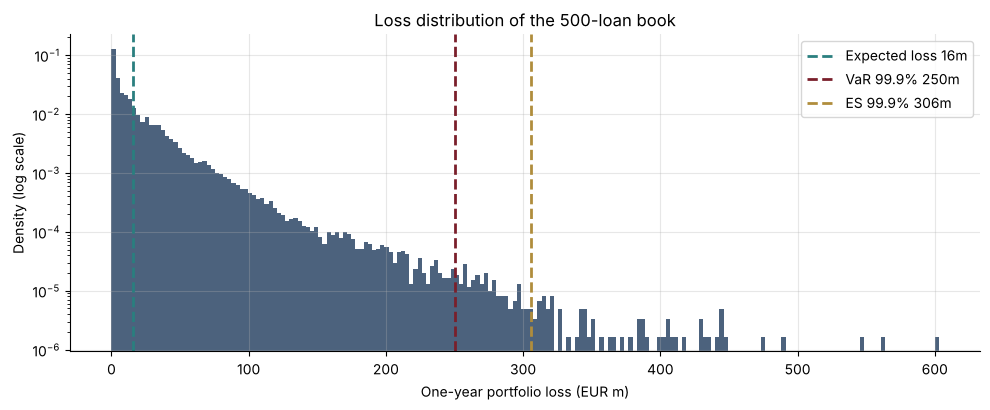

,EUR m
Expected loss,15.99
Std of loss,26.79
VaR 99.9%,250.36
ES 99.9%,305.50
Economic capital (VaR - EL),234.36
Basel IRB capital (sum of K x EAD),174.81
Capital / EAD,0.05


In [3]:
L = simulate_losses(ead, pd_, lgd, rho, n_sims=200_000, seed=1)
EL = (ead * pd_ * lgd).sum()
var999, es999 = var_es(L, 0.999)
irb = (basel_irb_capital(pd_, lgd, maturity=1.0) * ead).sum()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(L, bins=200, color=NAVY, alpha=0.8, density=True)
ax.set_yscale("log")
for x, lbl, c in [(EL, f"Expected loss {EL:.0f}m", TEAL), (var999, f"VaR 99.9% {var999:.0f}m", BORDEAUX), (es999, f"ES 99.9% {es999:.0f}m", GOLD)]:
    ax.axvline(x, color=c, lw=2, ls="--", label=lbl)
ax.set(xlabel="One-year portfolio loss (EUR m)", ylabel="Density (log scale)", title="Loss distribution of the 500-loan book")
ax.legend(); plt.tight_layout(); plt.savefig("images/loss_distribution.png", dpi=150); plt.show()
pd.Series({"Expected loss": EL, "Std of loss": L.std(), "VaR 99.9%": var999, "ES 99.9%": es999,
           "Economic capital (VaR - EL)": var999 - EL, "Basel IRB capital (sum of K x EAD)": irb,
           "Capital / EAD": (var999 - EL) / ead.sum()}).round(2).to_frame("EUR m")

**Reading the result.** The distribution is extremely skewed: most years cost close to
the expected loss, but the 1-in-1,000 year costs more than ten times as much. The
simulated economic capital is **above** the Basel IRB capital, although IRB uses the same
model in its large-pool closed form: IRB assumes an infinitely granular portfolio, while
this book has large single exposures. Section 3 isolates that effect.

## 3. Correlation, fat tails and concentration

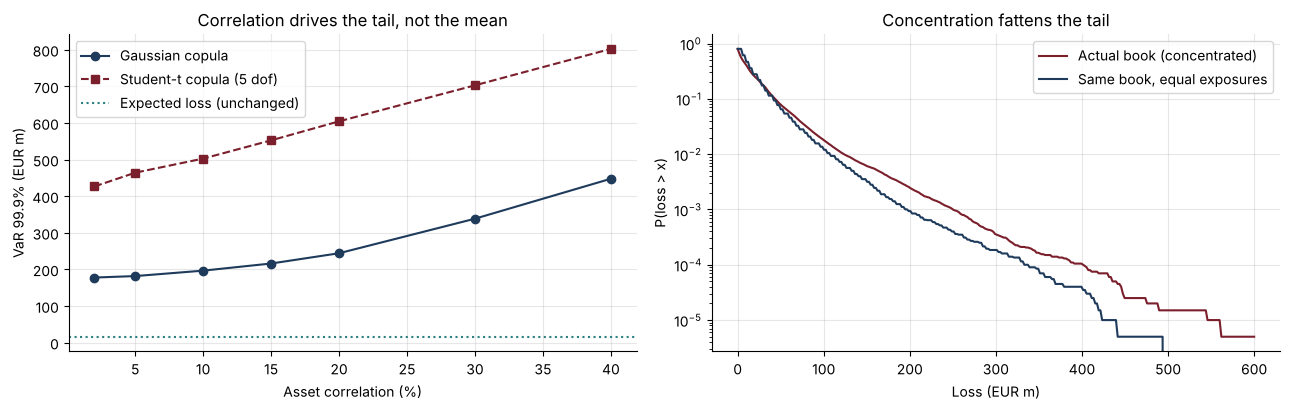

Top 10 exposures = 23.9% of the book.  VaR 99.9%: concentrated 250m vs granular 198m


In [4]:
rhos = [0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40]
gauss = [var_es(simulate_losses(ead, pd_, lgd, r_, 100_000, seed=2))[0] for r_ in rhos]
tcop = [var_es(simulate_losses(ead, pd_, lgd, r_, 100_000, seed=2, nu=5))[0] for r_ in rhos]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(np.array(rhos) * 100, gauss, "o-", color=NAVY, label="Gaussian copula")
axes[0].plot(np.array(rhos) * 100, tcop, "s--", color=BORDEAUX, label="Student-t copula (5 dof)")
axes[0].axhline(EL, color=TEAL, ls=":", label="Expected loss (unchanged)")
axes[0].set(xlabel="Asset correlation (%)", ylabel="VaR 99.9% (EUR m)", title="Correlation drives the tail, not the mean"); axes[0].legend()

granular_ead = np.full(500, ead.sum() / 500)
Lg = simulate_losses(granular_ead, pd_, lgd, rho, 200_000, seed=1)
x = np.linspace(0, 600, 300)
axes[1].plot(x, [(L > v).mean() for v in x], color=BORDEAUX, label="Actual book (concentrated)")
axes[1].plot(x, [(Lg > v).mean() for v in x], color=NAVY, label="Same book, equal exposures")
axes[1].set_yscale("log"); axes[1].set(xlabel="Loss (EUR m)", ylabel="P(loss > x)", title="Concentration fattens the tail")
axes[1].legend(); plt.tight_layout(); plt.savefig("images/tail_drivers.png", dpi=150); plt.show()
top10 = np.sort(ead)[-10:].sum() / ead.sum()
print(f"Top 10 exposures = {top10:.1%} of the book.  VaR 99.9%: concentrated {var999:.0f}m vs granular {var_es(Lg)[0]:.0f}m")

- **Correlation** leaves the expected loss unchanged but multiplies the tail: with
  independent defaults, bad years are rare; with correlated defaults they arrive together.
- The **Student-t copula** adds tail dependence: in a crisis, all borrowers are hit at once.
  Underestimating this was one of the modelling failures of 2007-2008.
- **Concentration**: the same PDs on equal-sized loans give a markedly lower VaR. Pillar 2
  capital add-ons exist for exactly this reason.

## 4. CDO tranches on a credit index

A synthetic CDO slices the losses of a 125-name index (like iTraxx Europe) into tranches.
The equity tranche (0-3%) absorbs the first losses, the senior tranche (22-100%) only
suffers in a catastrophe. With a large homogeneous pool, the expected loss of each
tranche is an integral over the common factor $Z$, which gives par spreads semi-analytically.

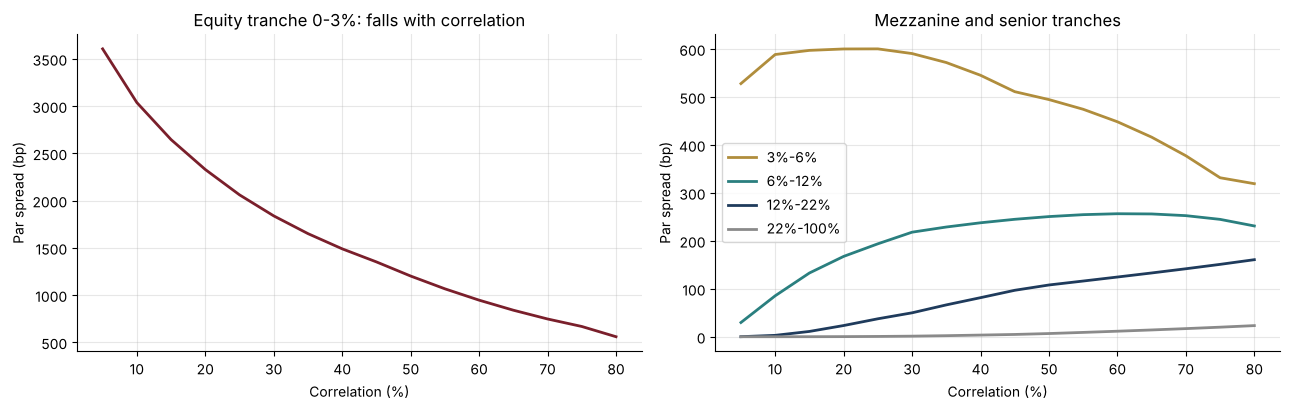

,0%-3%,3%-6%,6%-12%,12%-22%,22%-100%
0.1,3037.2,588.5,85.3,2.9,0.0
0.3,1837.9,590.4,218.0,49.8,1.2
0.5,1201.2,494.5,250.5,107.9,6.6
0.7,746.9,377.3,252.4,141.7,16.9


In [5]:
tranches = [(0.0, 0.03), (0.03, 0.06), (0.06, 0.12), (0.12, 0.22), (0.22, 1.0)]
labels = [f"{a:.0%}-{b:.0%}" for a, b in tranches]
hazard = 0.012                                   # index spread about 72 bp with 40% recovery
corrs = np.linspace(0.05, 0.8, 16)
spr = pd.DataFrame({lab: [tranche_par_spread(a, b, c, hazard) * 1e4 for c in corrs] for lab, (a, b) in zip(labels, tranches)},
                   index=np.round(corrs, 2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(corrs * 100, spr[labels[0]], color=BORDEAUX, lw=2)
axes[0].set(xlabel="Correlation (%)", ylabel="Par spread (bp)", title="Equity tranche 0-3%: falls with correlation")
for lab, c in zip(labels[1:], [GOLD, TEAL, NAVY, GREY]):
    axes[1].plot(corrs * 100, spr[lab], color=c, lw=2, label=lab)
axes[1].set(xlabel="Correlation (%)", ylabel="Par spread (bp)", title="Mezzanine and senior tranches"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/tranches.png", dpi=150); plt.show()
spr.iloc[[1, 5, 9, 13]].round(1)

**Reading the charts.** Higher correlation means either few defaults or many at once.
The equity tranche, hit by the first defaults, *benefits* (it is **long correlation**), while
senior tranches, hit only when many names default together, *suffer* (**short correlation**).
Mezzanine tranches sit in between, with a spread that first rises then falls.
In May 2005, when GM and Ford were downgraded, equity-tranche spreads widened while
correlation fell, and hedge funds long equity / short mezzanine lost on both legs.

## Conclusions
- The one-factor copula reproduces the expected loss for any correlation and the Vasicek
  closed form for a large pool (`test_copula.py`).
- Economic capital at 99.9% exceeds Basel IRB capital by about a third; equalising the
  exposures brings the VaR down from about 250m to about 200m, so the gap is concentration risk.
- Tranche values are driven by correlation, with opposite signs for equity and senior.
- **Next steps:** a multi-factor model with sectors, stochastic recovery, base-correlation
  calibration to market tranche quotes.